# Guided implementation: detecting a change in transmission loss

This notebook explains and runs the main computational workflow of [Guha, John, Gong and Basu, arXiv:2503.12276v2](https://arxiv.org/html/2503.12276v2).

We generate noisy optical measurements, convert each measurement into evidence, and stop when enough evidence supports a loss change. Then we compare coherent and squeezed light at the same average time between false alarms.

The teaching experiment uses an average run length (ARL) of **1,000 pulses**, so ordinary simulation is practical and early false alarms are visible. The paper's two-million-pulse comparisons are separate, already saved studies. This notebook does not resolve the remaining published-curve differences.

Run the cells in order with the project's Python environment. All scientific calculations call our implemented models and algorithms; NumPy supplies arrays/random draws, SciPy the numerical solver, and Matplotlib the plotting. No quantum SDK or quantum hardware is used.

In [1]:
from pathlib import Path
import csv
import json
import numpy as np
import matplotlib.pyplot as plt
from lossqcd.models import coherent_pair, squeezed_pair, coherent_kl, squeezed_kl
from lossqcd.entangled import entangled_kl_per_pulse
from lossqcd.cusum import page_cusum, detect_with_changepoint
from lossqcd.arl_solver import calibrate_numerical
from lossqcd.simulation import simulate_stopping_times, summarize_arl, summarize_delay

ROOT = Path(globals().get("PROJECT_ROOT", Path.cwd())).resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
OUTPUT = Path(globals().get("WALKTHROUGH_OUTPUT", ROOT / "walkthrough_interactive"))
OUTPUT.mkdir(parents=True, exist_ok=True)
N, Na, eta1, eta2 = 100.0, 0.1, 0.9, 0.85
TARGET_ARL, CHANGE_AT, TRIALS = 1000.0, 201, 12000
children = np.random.SeedSequence(2026102501).spawn(8)
seeds = [int(s.generate_state(1, dtype=np.uint64)[0]) for s in children]
pairs = {"coherent": coherent_pair(N, Na, eta1, eta2), "squeezed": squeezed_pair(N, Na, eta1, eta2)}
print("Study: N=100, Na=0.1, transmission 0.9 -> 0.85")
print("Teaching target: average no-change alarm time = 1,000 pulses")

Study: N=100, Na=0.1, transmission 0.9 -> 0.85
Teaching target: average no-change alarm time = 1,000 pulses


## 1. What does the detector measure?

For coherent light the measured quadrature is Gaussian: mean `sqrt(eta) * sqrt(N + Na)` and variance `1/4`. The energy is matched to the squeezed probe's total energy.

For squeezed light the mean is `sqrt(eta * N)`, and variance is `(eta * exp(-2r) + 1 - eta)/4`, where `r = asinh(sqrt(Na))`. Loss changes **both** its mean and variance.

The log-likelihood ratio (LLR) is `log(post-change density / pre-change density)`. A positive LLR supports a change; a negative LLR supports the original channel. Our Gaussian implementation includes the unequal-variance term.

coherent: mean 9.4916 -> 9.2242; variance 0.2500 -> 0.2500; KL=0.143029 nats
squeezed: mean 9.4868 -> 9.2195; variance 0.1458 -> 0.1515; KL=0.245469 nats


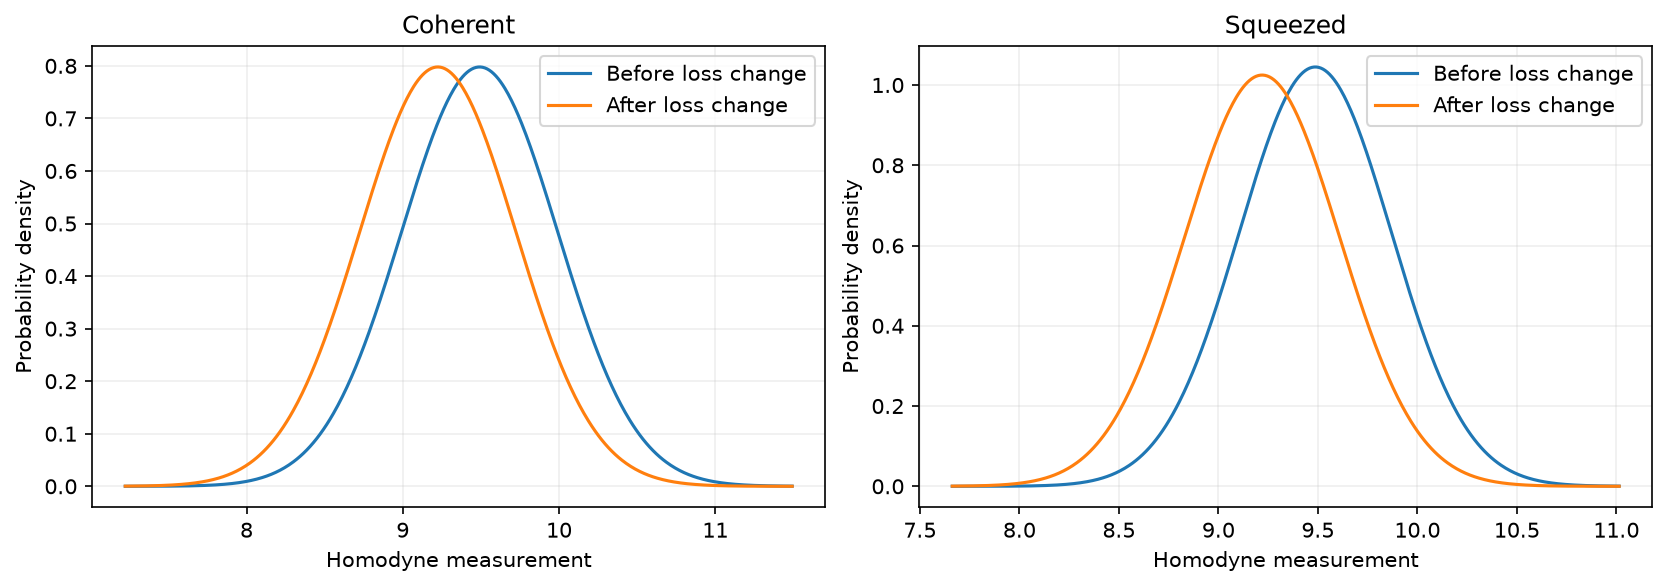

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
for ax, (name, (pre, post)) in zip(axes, pairs.items()):
    x = np.linspace(
        post.mean - 4 * np.sqrt(post.variance), pre.mean + 4 * np.sqrt(pre.variance), 600
    )
    ax.plot(x, np.exp(pre.logpdf(x)), label="Before loss change")
    ax.plot(x, np.exp(post.logpdf(x)), label="After loss change")
    ax.set(title=name.capitalize(), xlabel="Homodyne measurement", ylabel="Probability density")
    ax.legend()
    ax.grid(alpha=0.2)
    print(
        f"{name}: mean {pre.mean:.4f} -> {post.mean:.4f}; variance {pre.variance:.4f} -> {post.variance:.4f}; KL={post.kl(pre):.6f} nats"
    )
plt.show()

## 2. Recalculate the Figure 2 equations

KL divergence is the average evidence per changed measurement. Larger KL generally means faster detection at a fixed false-alarm requirement. The plot below evaluates the paper's coherent, squeezed and entangled formulas. It is an equation reproduction; no original numeric Figure 2 array is available for a pointwise comparison.

Entangled pulses are correlated. Their curve uses **joint block KL divided by block size**. It is not valid to feed individual marginal likelihoods into an independent detector and call that the entangled method. The pulse-level conditional detector lives in the separate correlated studies.

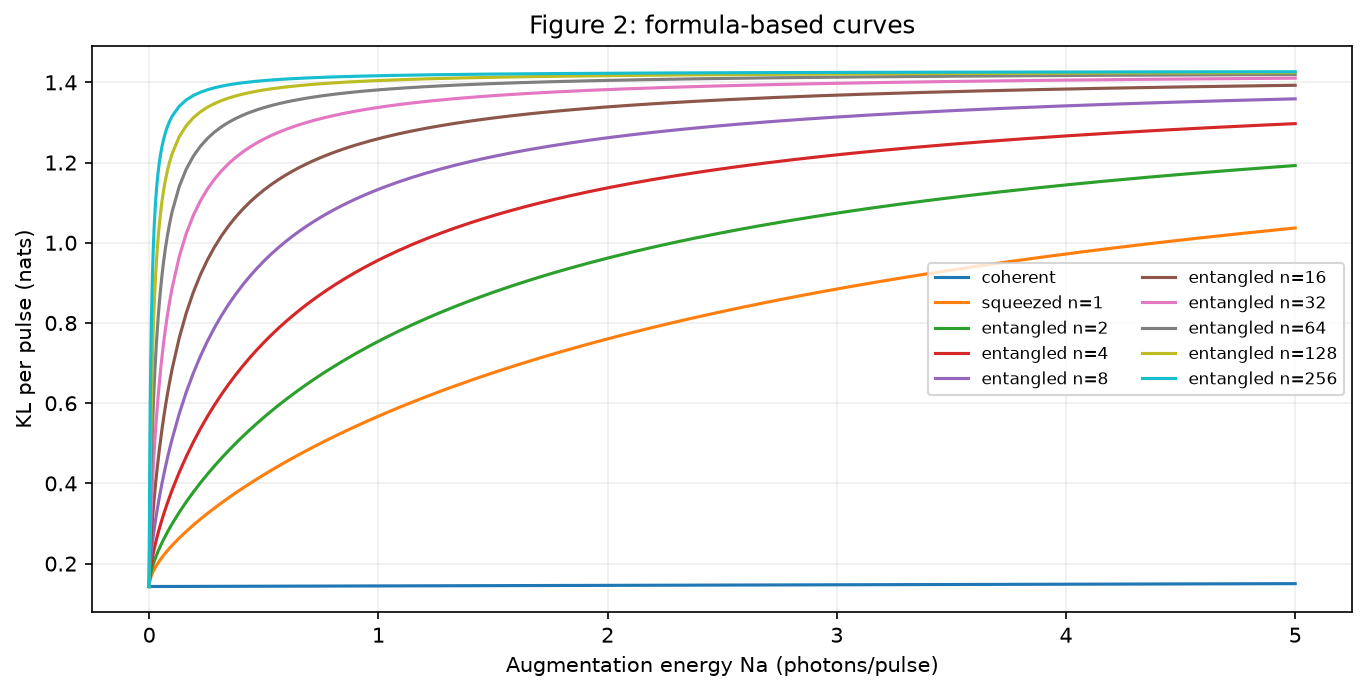

In [3]:
energies = np.unique(np.r_[0, np.geomspace(1e-5, 0.1, 80), np.linspace(0.1, 5, 160)])
curves = {
    "coherent": [coherent_kl(N, a, eta1, eta2) for a in energies],
    "squeezed n=1": [squeezed_kl(N, a, eta1, eta2) for a in energies],
}
for n in (2, 4, 8, 16, 32, 64, 128, 256):
    curves[f"entangled n={n}"] = [entangled_kl_per_pulse(N, a, eta1, eta2, n) for a in energies]
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
for label, values in curves.items():
    ax.plot(energies, values, label=label)
ax.set(
    xlabel="Augmentation energy Na (photons/pulse)",
    ylabel="KL per pulse (nats)",
    title="Figure 2: formula-based curves",
)
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.2)
with (OUTPUT / "figure2.csv").open("w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["Na", *curves])
    writer.writerows(zip(energies, *curves.values()))
plt.show()

## 3. Choose fair alarm thresholds

The detector keeps a running evidence score: `W[t] = max(0, W[t-1] + LLR[t])`. It alarms at the **first strict crossing** `W[t] > threshold`.

Using one threshold for both probes does not generally give the same false-alarm rate. We calibrate two thresholds to the same no-change ARL, using numerical first-step equations, and check the same thresholds on finer grids. Later, independent random observations check the ARL. The thresholds are never fitted to detection delays.

In [4]:
calibrations = {}
for name, (pre, post) in pairs.items():
    calibrations[name] = calibrate_numerical(
        pre, post, target_arl=TARGET_ARL, cells=256, check_cells=512, mesh_tolerance=0.005
    )
    c = calibrations[name]
    print(
        f"{name}: threshold={c['threshold']:.5f}, finer-grid ARL={c['grid_checks'][-1]['mean_stopping_time']:.2f}"
    )

coherent: threshold=4.38234, finer-grid ARL=1000.22
squeezed: threshold=4.68477, finer-grid ARL=1000.16


## 4. Watch one trajectory

The true channel changes on pulse 201. The detector knows the possible pre/post laws, but does not receive the true change time.

The dashed vertical line marks the true change for **our evaluation only**. An alarm before that line is a false alarm, not a successful detection. The estimated change time is calculated from the likelihood path only when an alarm occurs. One trajectory is an illustration, not a performance estimate.

coherent {'stop': 262, 'estimated_change_at': 203, 'statistic': 4.6956702986791115} early false alarm: False
squeezed {'stop': 207, 'estimated_change_at': 194, 'statistic': 4.753688663899933} early false alarm: False


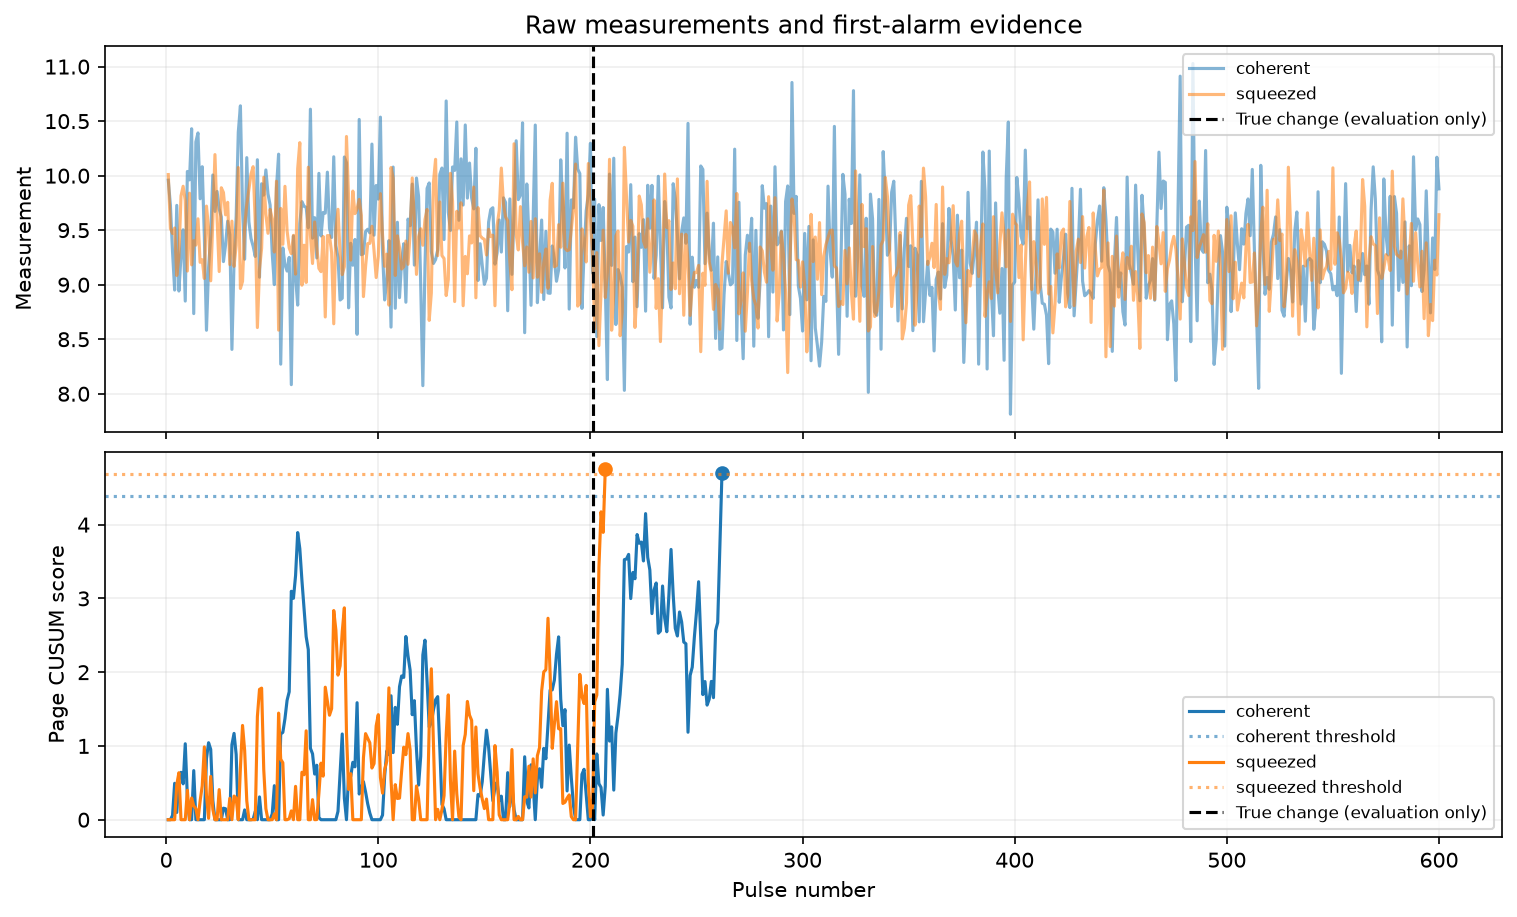

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout="constrained")
trace_results = {}
for i, (name, (pre, post)) in enumerate(pairs.items()):
    color = {"coherent": "tab:blue", "squeezed": "tab:orange"}[name]
    rng = np.random.default_rng(seeds[i])
    x = np.r_[
        rng.normal(pre.mean, np.sqrt(pre.variance), CHANGE_AT - 1),
        rng.normal(post.mean, np.sqrt(post.variance), 601 - CHANGE_AT),
    ]
    llrs = post.llr(x, pre)
    threshold = calibrations[name]["threshold"]
    result = detect_with_changepoint(llrs, threshold)
    trace_results[name] = result
    t = np.arange(1, len(x) + 1)
    axes[0].plot(t, x, alpha=0.55, color=color, label=name)
    end = result["stop"] or len(x)
    axes[1].plot(t[:end], page_cusum(llrs)[:end], color=color, label=name)
    axes[1].axhline(threshold, ls=":", alpha=0.6, color=color, label=f"{name} threshold")
    if result["stop"] is not None:
        axes[1].plot(result["stop"], result["statistic"], "o", color=color)
    print(
        name,
        result,
        "early false alarm:",
        result["stop"] is not None and result["stop"] < CHANGE_AT,
    )
for ax in axes:
    ax.axvline(CHANGE_AT, color="black", ls="--", label="True change (evaluation only)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
axes[0].set(ylabel="Measurement", title="Raw measurements and first-alarm evidence")
axes[1].set(xlabel="Pulse number", ylabel="Page CUSUM score")
plt.show()

## 5. Measure performance across many independent runs

For each probe we generate separate no-change runs and changed runs. The no-change average first-alarm time estimates ARL. For changed runs we report two quantities separately:

- How many first alarms happened **before** pulse 201.
- Average `alarm time - 201`, **conditional on no earlier alarm**.

An alarm on the first changed pulse has delay zero. We do not reset an early false alarm and relabel a later alarm as the detector's first detection. These conditional averages are not Lorden worst-case delays. Error bars are approximate Monte Carlo uncertainty.

coherent {
  "threshold": 4.382344951756148,
  "arl": {
    "trials": 12000,
    "horizon": 100000,
    "censored": 0,
    "arl": 979.9414166666667,
    "arl_se": 8.749396220845863,
    "restricted_mean_min_T_H": 979.9414166666667,
    "restricted_mean_se": 8.749396220845863
  },
  "delay": {
    "trials": 12000,
    "change_at": 201,
    "horizon": 5000,
    "false_alarms": 2051,
    "false_alarm_probability": 0.17091666666666666,
    "false_alarm_probability_se": 0.0034363759946856587,
    "survivors": 9949,
    "post_change_censored": 0,
    "conditional_delay": 24.27902301738868,
    "conditional_delay_se": 0.16226364290249953,
    "restricted_conditional_delay": 24.27902301738868,
    "restricted_conditional_delay_se": 0.16226364290249953
  }
}
squeezed {
  "threshold": 4.684774859861131,
  "arl": {
    "trials": 12000,
    "horizon": 100000,
    "censored": 0,
    "arl": 1010.7455833333333,
    "arl_se": 9.062184120333324,
    "restricted_mean_min_T_H": 1010.7455833333333,
    "r

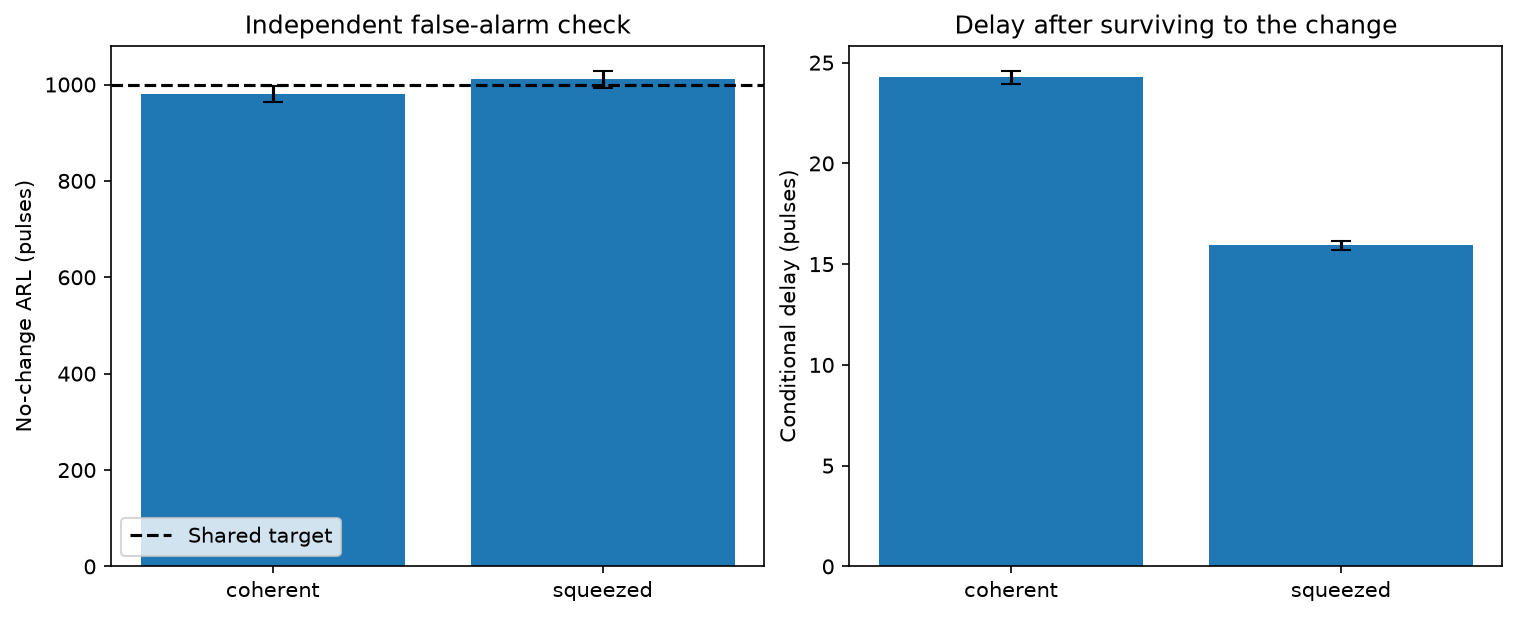

In [6]:
results = {}
for i, (name, (pre, post)) in enumerate(pairs.items()):
    h = calibrations[name]["threshold"]
    null = simulate_stopping_times(pre, post, h, trials=TRIALS, horizon=100000, seed=seeds[2 + i])
    changed = simulate_stopping_times(
        pre, post, h, trials=TRIALS, horizon=5000, change_at=CHANGE_AT, seed=seeds[4 + i]
    )
    arl, delay = summarize_arl(null), summarize_delay(changed)
    results[name] = {"threshold": h, "arl": arl, "delay": delay}
    np.savez_compressed(
        OUTPUT / f"{name}_runs.npz",
        null_stop=null.stop,
        null_event=null.event,
        changed_stop=changed.stop,
        changed_event=changed.event,
    )
    print(name, json.dumps(results[name], indent=2))
    assert arl["arl"] is not None, "Censored no-change runs: unrestricted ARL unavailable."
    assert delay["conditional_delay"] is not None, (
        "Censored changed runs: unrestricted delay unavailable."
    )
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
names = list(results)
axes[0].bar(
    names,
    [results[n]["arl"]["arl"] for n in names],
    yerr=[1.96 * results[n]["arl"]["arl_se"] for n in names],
    capsize=5,
)
axes[0].axhline(TARGET_ARL, ls="--", color="black", label="Shared target")
axes[0].set(ylabel="No-change ARL (pulses)", title="Independent false-alarm check")
axes[0].legend()
axes[1].bar(
    names,
    [results[n]["delay"]["conditional_delay"] for n in names],
    yerr=[1.96 * results[n]["delay"]["conditional_delay_se"] for n in names],
    capsize=5,
)
axes[1].set(ylabel="Conditional delay (pulses)", title="Delay after surviving to the change")
plt.show()

## 6. Why stopping a simulation too soon can mislead

If a no-change run ends without an alarm, its true stopping time is unknown. Averaging only the observed alarm times can make a detector look worse than it is.

Our summary returns `arl=None` when any run is right-censored, and exposes the restricted average `E[min(T, horizon)]` instead. That restricted value is a lower bound on the unrestricted ARL. The same principle applies to censored detection delays.

In [7]:
pre, post = pairs["coherent"]
short = simulate_stopping_times(
    pre, post, calibrations["coherent"]["threshold"], trials=1000, horizon=20, seed=seeds[6]
)
censor_demo = summarize_arl(short)
print(json.dumps(censor_demo, indent=2))
assert censor_demo["censored"] > 0 and censor_demo["arl"] is None
summary = {
    "settings": {
        "N": N,
        "Na": Na,
        "eta1": eta1,
        "eta2": eta2,
        "target_arl": TARGET_ARL,
        "change_at": CHANGE_AT,
        "trials": TRIALS,
        "seeds": seeds,
    },
    "calibrations": calibrations,
    "single_traces": trace_results,
    "results": results,
    "censoring_demo": censor_demo,
    "paper_figure_reproduction_claimed": False,
}
(OUTPUT / "lesson_summary.json").write_text(json.dumps(summary, indent=2) + "\n")
print("Saved numerical summary and all first-alarm arrays to", OUTPUT)

{
  "trials": 1000,
  "horizon": 20,
  "censored": 988,
  "arl": null,
  "arl_se": null,
  "restricted_mean_min_T_H": 19.95,
  "restricted_mean_se": 0.01832582428803233
}
Saved numerical summary and all first-alarm arrays to walkthrough_run_v2
